# 06 - Main comparison (headline)

**Owner:** Member 4
**Task:** Most-popular, BPR-MF and LightGCN on KuaiRand-Pure and KuaiRec, scored on the biased `test` and on `test_unbiased`. BPR-MF and LightGCN use the best validation settings from notebooks 03 and 04, 3 seeds. Report Recall@20, NDCG@20, the margin over most-popular, coverage, popularity of recommendations and training time as mean ± std; say when a gap is within noise. The unbiased test is scored two ways: exposure-only (GAUC and NDCG@5 over the videos each user was shown, the headline protocol decided on 2026-10-11) and full ranking (Recall@20, NDCG@20; on KuaiRec only among the block videos, where Recall@20 is capped at about 0.32). Headline figure: the methods on the two tests, both datasets.
**Inputs:** the selected settings of notebooks 03 and 04 (`experiments.run_grid.SELECTED`), `data/processed/*.npz`
**Outputs:** results/06_main_comparison_<dataset>.json (every run), results/06_main_comparison.json (tables), results/06_headline.png

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import models
import training
import inference

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)


## Experiments

### Settings and runs

Every model is trained on the same splits and seeds (fairness rule 1), with the BPR loss, uniform negative sampling, batch 2048, at most 100 epochs and early stopping on validation Recall@20 every 5 epochs with patience 4 (rules 3 and 4). The settings are the validation selections of notebooks 03 and 04:

| Dataset | BPR-MF | LightGCN |
|---|---|---|
| KuaiRand-Pure | dim 64, lr 1e-3, L2 1e-3 | 3 layers, dim 128, lr 1e-3, L2 1e-4 |
| KuaiRec | dim 64, lr 3e-4, L2 1e-4 | 3 layers, dim 128, lr 1e-3, L2 1e-4 |

The selections give LightGCN twice BPR-MF's embedding size, which breaks rule 3 (same embedding dimension, so the graph is the only difference). A fourth row, **LightGCN (dim 64)**, is the control: the best dim-64 configuration of notebook 04's grid on both datasets (3 layers, lr 1e-3, L2 1e-4). Most-popular is not trained; it is scored on each seed's split.

Runs are cached in `results/06_main_comparison_<dataset>*.json` and skipped when finished. They were produced in four parallel processes:

```bash
python src/experiments/run_grid.py 06 kuairand 06 kuairec 05 kuairand 05 kuairec --seeds=0,1,2 --shard=i/4 --threads=2   # i = 0..3
```

In [2]:
from IPython.display import Image
from scipy.stats import ttest_rel
from experiments.run_grid import LIGHTGCN_DIM64, SELECTED, merge_runs, run_grid
from utils.io import save_json, savefig

DATASETS = ("kuairand", "kuairec")
for name in DATASETS:
    run_grid("06", name, seeds=SEEDS)
runs = merge_runs("06", DATASETS)
print(len(runs), "runs cached")

18 runs cached


### All runs

One row per dataset, method and seed. `gauc` and `ndcg5` are the exposure-only metrics on the unbiased test; `unb_*` are the full-ranking ones. `s_per_epoch` is wall time divided by the epochs run (validation every 5 epochs included); all trained runs shared one 8-core laptop, four at a time with 2 threads each, so times compare the models with each other rather than measure a dedicated machine. `params` is the number of embedding parameters.

In [3]:
LABELS = {"kuairand": "KuaiRand-Pure", "kuairec": "KuaiRec"}
ORDER = ["Most-popular", "BPR-MF", "LightGCN", "LightGCN (dim 64)"]


def method(r):
    c = r["cfg"]
    if c["model"] == "mf":
        return "BPR-MF"
    return "LightGCN" if c["dim"] == SELECTED[r["dataset"]]["lightgcn"]["dim"] else "LightGCN (dim 64)"


def row(name, label, seed, test, unb, exp, **extra):
    return dict(dataset=name, method=label, seed=seed,
                recall=test["recall"], ndcg=test["ndcg"], coverage=test["coverage"], popularity=test["popularity"],
                gauc=exp["gauc"], ndcg5=exp["ndcg"], unb_recall=unb["recall"], unb_ndcg=unb["ndcg"],
                unb_coverage=unb["coverage"], unb_popularity=unb["popularity"], **extra)


rows = []
for name in DATASETS:
    for seed in SEEDS:
        ds = data.load_processed(name, seed=seed)
        mp = models.MostPopular(ds)
        rows.append(row(name, "Most-popular", seed,
                        inference.evaluate(mp, ds, "test", mask_splits=("train", "val"))[0],
                        inference.evaluate(mp, ds, "test_unbiased", mask_splits=("train", "val", "test"))[0],
                        inference.evaluate_exposed(mp, ds)[0]))
        n_nodes = ds["n_users"] + ds["n_items"]
        for r in runs.values():
            if r["dataset"] == name and r["seed"] == seed:
                rows.append(row(name, method(r), seed, r["test"], r["test_unbiased"], r["test_exposed"],
                                val_recall=r["val_recall"], best_epoch=r["best_epoch"], epochs=r["epochs_run"],
                                train_time=r["train_time"], s_per_epoch=r["train_time"] / r["epochs_run"],
                                params=n_nodes * r["cfg"]["dim"]))
df = pd.DataFrame(rows)
df["method"] = pd.Categorical(df.method, ORDER, ordered=True)
df = df.sort_values(["dataset", "method", "seed"]).reset_index(drop=True)
assert len(df) == len(DATASETS) * len(ORDER) * len(SEEDS), "some runs are missing"
df.round(4)

,dataset,method,seed,recall,ndcg,coverage,popularity,gauc,ndcg5,unb_recall,unb_ndcg,unb_coverage,unb_popularity,val_recall,best_epoch,epochs,train_time,s_per_epoch,params
0,kuairand,Most-popular,0,0.1141,0.0761,0.0053,2064.2757,0.5828,0.3621,0.0068,0.0046,0.0061,2029.1990,NaN,NaN,NaN,NaN,NaN,NaN
1,kuairand,Most-popular,1,0.1124,0.0754,0.0054,2065.1018,0.5823,0.3625,0.0067,0.0046,0.0061,2030.2765,NaN,NaN,NaN,NaN,NaN,NaN
2,kuairand,Most-popular,2,0.1095,0.0746,0.0057,2068.4716,0.5821,0.3618,0.0066,0.0046,0.0061,2034.1469,NaN,NaN,NaN,NaN,NaN,NaN
3,kuairand,BPR-MF,0,0.1693,0.1102,0.6164,820.1633,0.6123,0.3995,0.0060,0.0041,0.5855,824.2936,0.1673,100.0,100.0,480.6161,4.8062,2106048.0
4,kuairand,BPR-MF,1,0.1689,0.1107,0.6137,838.6670,0.6123,0.4015,0.0057,0.0038,0.5797,843.6361,0.1634,90.0,100.0,480.0371,4.8004,2106048.0
5,kuairand,BPR-MF,2,0.1632,0.1082,0.6201,864.7151,0.6143,0.3985,0.0053,0.0036,0.5937,869.9666,0.1657,75.0,95.0,455.4616,4.7943,2106048.0
6,kuairand,LightGCN,0,0.2179,0.1461,0.4903,923.1558,0.6140,0.4067,0.0063,0.0041,0.4602,922.5441,0.2109,95.0,100.0,9873.3649,98.7336,4212096.0
7,kuairand,LightGCN,1,0.2183,0.1461,0.5080,907.4418,0.6152,0.4073,0.0060,0.0039,0.4861,907.3488,0.2107,100.0,100.0,9713.7599,97.1376,4212096.0
8,kuairand,LightGCN,2,0.2131,0.1437,0.4974,910.9494,0.6148,0.4069,0.0062,0.0041,0.4745,911.0990,0.2142,100.0,100.0,9713.9917,97.1399,4212096.0
9,kuairand,LightGCN (dim 64),0,0.2051,0.1380,0.3660,1001.7860,0.6182,0.4085,0.0064,0.0042,0.3465,1001.5871,0.1993,100.0,100.0,6011.7632,60.1176,2106048.0


### Summary, mean ± std over 3 seeds

Standard deviations are sample standard deviations (ddof=1) over the three seeds. Random rankers score GAUC 0.5; random NDCG@5 over the shown videos is about 0.26 on KuaiRand-Pure (19% of shown videos are clicked), so NDCG@5 is read against that floor.

In [4]:
def pm(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"


BIASED = ["recall", "ndcg", "coverage", "popularity"]
UNBIASED = ["gauc", "ndcg5", "unb_recall", "unb_ndcg", "unb_coverage", "unb_popularity"]
COST = ["val_recall", "best_epoch", "epochs", "s_per_epoch", "train_time", "params"]
summary = df.groupby(["dataset", "method"], observed=True)[BIASED + UNBIASED + COST].agg(pm)
summary[BIASED]

recall             ndcg         coverage  \
dataset  method                                                                 
kuairand Most-popular       0.1120 ± 0.0023  0.0754 ± 0.0007  0.0054 ± 0.0002   
         BPR-MF             0.1672 ± 0.0034  0.1097 ± 0.0013  0.6167 ± 0.0032   
         LightGCN           0.2164 ± 0.0029  0.1453 ± 0.0014  0.4986 ± 0.0089   
         LightGCN (dim 64)  0.2040 ± 0.0032  0.1366 ± 0.0018  0.3691 ± 0.0086   
kuairec  Most-popular       0.0730 ± 0.0012  0.0878 ± 0.0012  0.0045 ± 0.0002   
         BPR-MF             0.1071 ± 0.0023  0.1141 ± 0.0013  0.1282 ± 0.0427   
         LightGCN           0.1278 ± 0.0034  0.1379 ± 0.0025  0.2493 ± 0.0233   
         LightGCN (dim 64)  0.1252 ± 0.0035  0.1346 ± 0.0016  0.1725 ± 0.0083   

                                    popularity  
dataset  method                                 
kuairand Most-popular       2065.9497 ± 2.2227  
         BPR-MF             841.1818 ± 22.3821  
         LightGCN            913.8490 ± 8.2486  
         LightGCN (dim 64)  1002.2045 ± 2.9032  
kuairec  Most-popular       1112.3004 ± 4.1450  
         BPR-MF             745.2207 ± 43.5459  
         LightGCN            650.3592 ± 9.3758  
         LightGCN (dim 64)   680.7662 ± 5.6420

In [5]:
summary[UNBIASED]

gauc            ndcg5       unb_recall  \
dataset  method                                                                 
kuairand Most-popular       0.5824 ± 0.0004  0.3622 ± 0.0004  0.0067 ± 0.0001   
         BPR-MF             0.6130 ± 0.0012  0.3998 ± 0.0015  0.0057 ± 0.0004   
         LightGCN           0.6147 ± 0.0006  0.4070 ± 0.0003  0.0062 ± 0.0002   
         LightGCN (dim 64)  0.6183 ± 0.0005  0.4085 ± 0.0004  0.0063 ± 0.0001   
kuairec  Most-popular       0.7612 ± 0.0001  0.6752 ± 0.0000  0.1533 ± 0.0048   
         BPR-MF             0.7757 ± 0.0038  0.6291 ± 0.0207  0.1758 ± 0.0026   
         LightGCN           0.7357 ± 0.0028  0.5557 ± 0.0114  0.1633 ± 0.0022   
         LightGCN (dim 64)  0.7398 ± 0.0015  0.5883 ± 0.0045  0.1703 ± 0.0003   

                                   unb_ndcg     unb_coverage  \
dataset  method                                                
kuairand Most-popular       0.0046 ± 0.0000  0.0061 ± 0.0000   
         BPR-MF             0.0038 ± 0.0002  0.5863 ± 0.0070   
         LightGCN           0.0041 ± 0.0001  0.4736 ± 0.0130   
         LightGCN (dim 64)  0.0042 ± 0.0001  0.3514 ± 0.0061   
kuairec  Most-popular       0.5482 ± 0.0076  0.0060 ± 0.0000   
         BPR-MF             0.5742 ± 0.0111  0.1007 ± 0.0310   
         LightGCN           0.4950 ± 0.0115  0.4017 ± 0.0355   
         LightGCN (dim 64)  0.5259 ± 0.0032  0.2330 ± 0.0274   

                                 unb_popularity  
dataset  method                                  
kuairand Most-popular        2031.2075 ± 2.6020  
         BPR-MF              845.9655 ± 22.9254  
         LightGCN             913.6640 ± 7.9157  
         LightGCN (dim 64)   1003.0243 ± 3.1046  
kuairec  Most-popular        1136.4333 ± 4.5369  
         BPR-MF             1045.6868 ± 17.2076  
         LightGCN            805.9054 ± 17.6338  
         LightGCN (dim 64)    882.5392 ± 9.1420

In [6]:
cost = df[df.method != "Most-popular"].groupby(["dataset", "method"], observed=True)[COST].mean()
cost.round({"val_recall": 4, "best_epoch": 1, "epochs": 1, "s_per_epoch": 1, "train_time": 0, "params": 0})

val_recall  best_epoch  epochs  s_per_epoch  \
dataset  method                                                           
kuairand BPR-MF                 0.1655        88.3    98.3          4.8   
         LightGCN               0.2119        98.3   100.0         97.7   
         LightGCN (dim 64)      0.2000       100.0   100.0         49.0   
kuairec  BPR-MF                 0.1055        61.7    81.7          3.2   
         LightGCN               0.1269        93.3   100.0         87.0   
         LightGCN (dim 64)      0.1234        98.3   100.0         45.8   

                            train_time     params  
dataset  method                                    
kuairand BPR-MF                  472.0  2106048.0  
         LightGCN               9767.0  4212096.0  
         LightGCN (dim 64)      4895.0  2106048.0  
kuairec  BPR-MF                  250.0  1138176.0  
         LightGCN               8701.0  2276352.0  
         LightGCN (dim 64)      4576.0  1138176.0

### Margin over most-popular

Per seed, model minus most-popular on the same split, then mean ± std; `rel` is the mean relative margin.

In [7]:
HEADLINE = {"recall": "biased Recall@20", "ndcg": "biased NDCG@20", "gauc": "unbiased GAUC",
            "ndcg5": "unbiased NDCG@5", "unb_recall": "unbiased Recall@20 (full)", "unb_ndcg": "unbiased NDCG@20 (full)"}
wide = df.pivot_table(index=["dataset", "seed"], columns="method", values=list(HEADLINE), observed=True)
margins = []
for name in DATASETS:
    w = wide.loc[name]
    for m in ORDER[1:]:
        for metric, label in HEADLINE.items():
            d = w[(metric, m)] - w[(metric, "Most-popular")]
            margins.append(dict(dataset=name, method=m, metric=label, margin=pm(d),
                                rel=f"{(d / w[(metric, 'Most-popular')]).mean():+.1%}"))
margins = pd.DataFrame(margins)
margins.pivot_table(index=["dataset", "method"], columns="metric", values="margin", aggfunc="first", observed=True)[list(HEADLINE.values())]

metric                     biased Recall@20   biased NDCG@20  \
dataset  method                                                
kuairand BPR-MF             0.0552 ± 0.0014  0.0343 ± 0.0008   
         LightGCN           0.1045 ± 0.0012  0.0699 ± 0.0008   
         LightGCN (dim 64)  0.0920 ± 0.0018  0.0612 ± 0.0011   
kuairec  BPR-MF             0.0341 ± 0.0016  0.0263 ± 0.0004   
         LightGCN           0.0548 ± 0.0031  0.0501 ± 0.0017   
         LightGCN (dim 64)  0.0522 ± 0.0030  0.0468 ± 0.0005   

metric                         unbiased GAUC   unbiased NDCG@5  \
dataset  method                                                  
kuairand BPR-MF              0.0306 ± 0.0015   0.0377 ± 0.0012   
         LightGCN            0.0323 ± 0.0009   0.0448 ± 0.0003   
         LightGCN (dim 64)   0.0360 ± 0.0007   0.0464 ± 0.0000   
kuairec  BPR-MF              0.0145 ± 0.0037  -0.0461 ± 0.0207   
         LightGCN           -0.0255 ± 0.0027  -0.1195 ± 0.0114   
         LightGCN (dim 64)  -0.0214 ± 0.0015  -0.0868 ± 0.0045   

metric                     unbiased Recall@20 (full) unbiased NDCG@20 (full)  
dataset  method                                                               
kuairand BPR-MF                     -0.0010 ± 0.0003        -0.0008 ± 0.0002  
         LightGCN                   -0.0005 ± 0.0001        -0.0005 ± 0.0001  
         LightGCN (dim 64)          -0.0004 ± 0.0001        -0.0005 ± 0.0000  
kuairec  BPR-MF                      0.0225 ± 0.0028         0.0259 ± 0.0037  
         LightGCN                    0.0100 ± 0.0033        -0.0532 ± 0.0061  
         LightGCN (dim 64)           0.0170 ± 0.0046        -0.0224 ± 0.0044

### Is LightGCN's gap over BPR-MF real? (fairness rule 5)

Paired over the three seeds (same split per seed): mean and std of the per-seed gap, LightGCN wins out of 3, and a paired t-test. With three seeds the test has two degrees of freedom, so a gap counts as **within noise** unless p < 0.05; that is a strict bar and is stated as such in the report.

In [8]:
gaps = []
for name in DATASETS:
    w = wide.loc[name]
    for model in ("LightGCN", "LightGCN (dim 64)"):
        for metric, label in HEADLINE.items():
            a, b = w[(metric, model)], w[(metric, "BPR-MF")]
            d = a - b
            p = ttest_rel(a, b).pvalue
            gaps.append(dict(dataset=name, comparison=f"{model} - BPR-MF", metric=label, gap=d.mean(), std=d.std(ddof=1),
                             rel=d.mean() / b.mean(), wins=f"{(d > 0).sum()}/{len(d)}", p=p,
                             verdict="within noise" if not p < 0.05 else ("LightGCN" if d.mean() > 0 else "BPR-MF")))
gaps = pd.DataFrame(gaps)
gaps.round(4)

,dataset,comparison,metric,gap,std,rel,wins,p,verdict
0,kuairand,LightGCN - BPR-MF,biased Recall@20,0.0493,0.0007,0.2948,3/3,0.0001,LightGCN
1,kuairand,LightGCN - BPR-MF,biased NDCG@20,0.0356,0.0003,0.3244,3/3,0.0000,LightGCN
2,kuairand,LightGCN - BPR-MF,unbiased GAUC,0.0017,0.0012,0.0027,3/3,0.1431,within noise
3,kuairand,LightGCN - BPR-MF,unbiased NDCG@5,0.0071,0.0013,0.0179,3/3,0.0109,LightGCN
4,kuairand,LightGCN - BPR-MF,unbiased Recall@20 (full),0.0005,0.0004,0.0828,3/3,0.1532,within noise
5,kuairand,LightGCN - BPR-MF,unbiased NDCG@20 (full),0.0002,0.0002,0.0559,3/3,0.2301,within noise
6,kuairand,LightGCN (dim 64) - BPR-MF,biased Recall@20,0.0368,0.0009,0.2202,3/3,0.0002,LightGCN
7,kuairand,LightGCN (dim 64) - BPR-MF,biased NDCG@20,0.0269,0.0008,0.2452,3/3,0.0003,LightGCN
8,kuairand,LightGCN (dim 64) - BPR-MF,unbiased GAUC,0.0053,0.0008,0.0087,3/3,0.0067,LightGCN
9,kuairand,LightGCN (dim 64) - BPR-MF,unbiased NDCG@5,0.0087,0.0012,0.0218,3/3,0.0060,LightGCN


### Headline figure

Recall@20 on the biased test and GAUC on the unbiased test (exposure-only), mean over 3 seeds with ±1 std error bars. The GAUC bars start at the random ranker's 0.5, so their length is the lift over random.

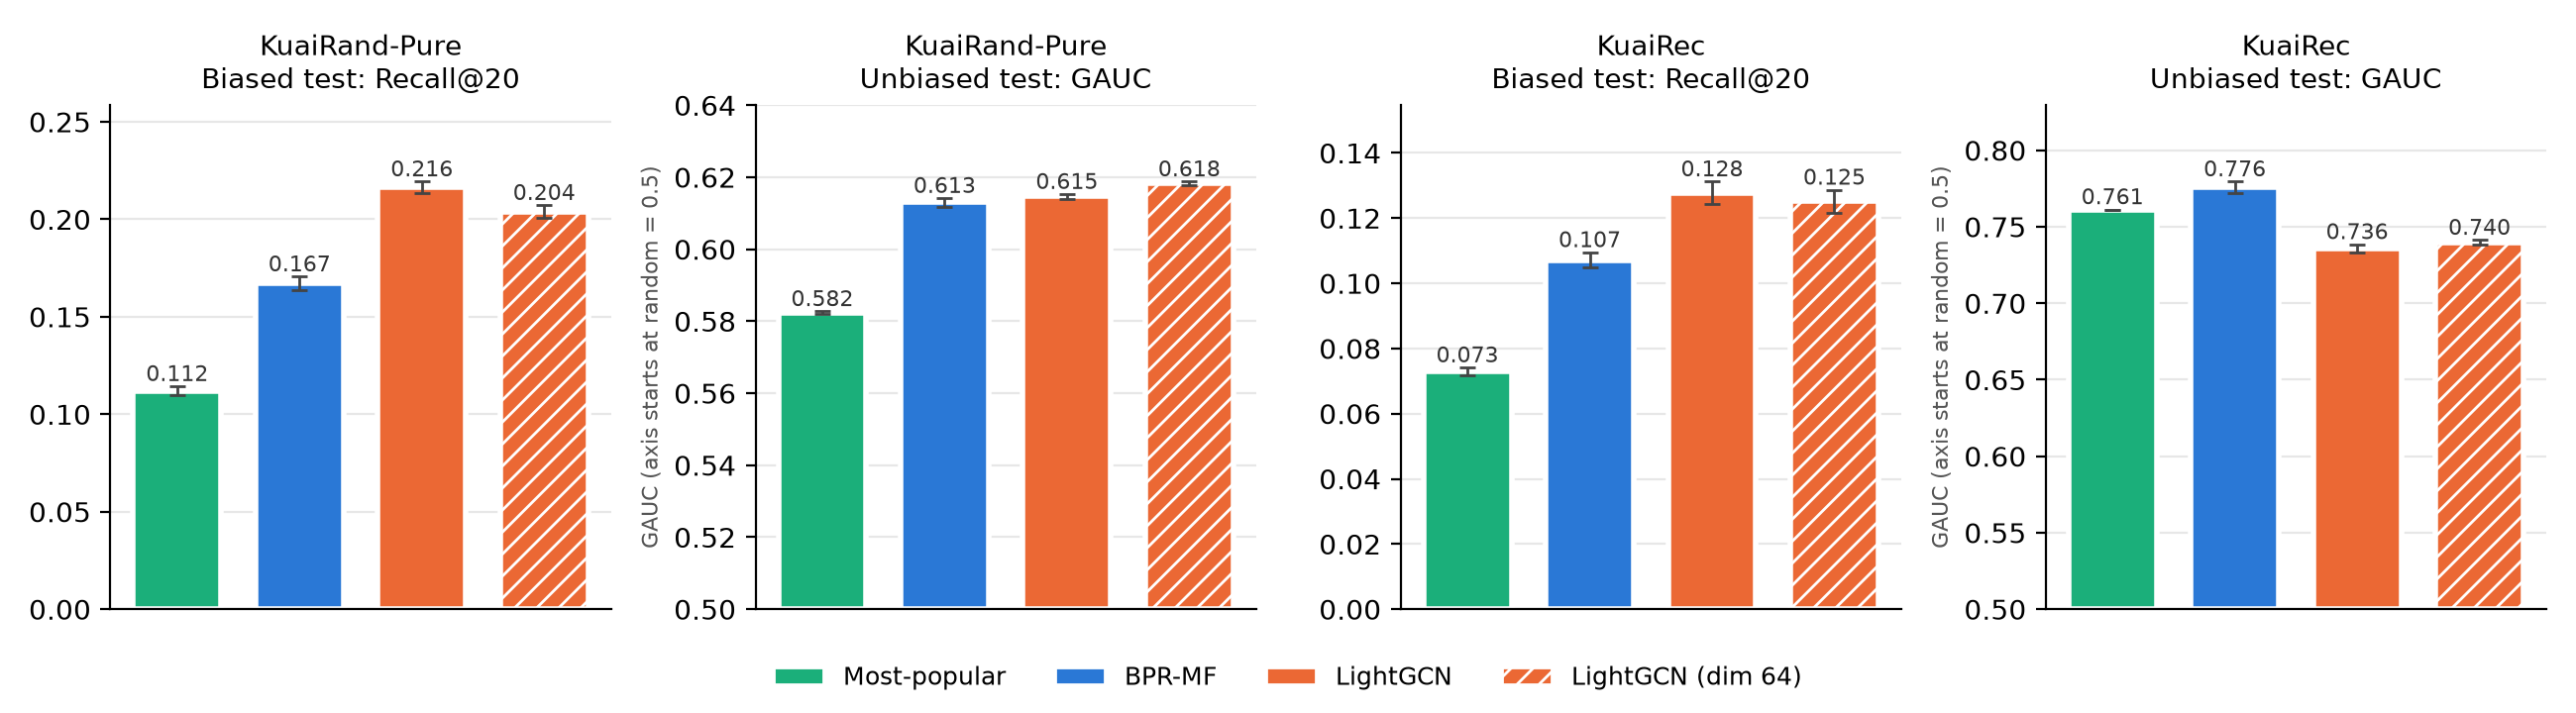

In [9]:
COLORS = {"Most-popular": "#1baf7a", "BPR-MF": "#2a78d6", "LightGCN": "#eb6834", "LightGCN (dim 64)": "#eb6834"}
PANELS = [("recall", "Biased test: Recall@20", 0.0), ("gauc", "Unbiased test: GAUC", 0.5)]
agg = df.groupby(["dataset", "method"], observed=True)[["recall", "gauc"]].agg(["mean", "std"])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, (metric, title, base)) in zip(axes, [(n, p) for n in DATASETS for p in PANELS]):
    for x, m in enumerate(ORDER):
        mean, std = agg.loc[(name, m), (metric, "mean")], agg.loc[(name, m), (metric, "std")]
        ax.bar(x, mean - base, bottom=base, width=0.72, color=COLORS[m], edgecolor="white", linewidth=2,
               hatch="///" if "dim 64" in m else None, yerr=std, capsize=3, error_kw=dict(lw=1, ecolor="#444"))
        ax.text(x, mean + std, f"{mean:.3f}", ha="center", va="bottom", fontsize=8, color="#333")
    if base:
        ax.set_ylabel("GAUC (axis starts at random = 0.5)", fontsize=8, color="#555")
    top = (agg.loc[name][(metric, "mean")] + agg.loc[name][(metric, "std")]).max()
    ax.set_ylim(base, base + (top - base) * 1.18)
    ax.set_xticks([])
    ax.set_title(f"{LABELS[name]}\n{title}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, fc=COLORS[m], ec="white", hatch="///" if "dim 64" in m else None) for m in ORDER]
fig.legend(handles, ORDER, loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
savefig(fig, "06_headline.png")
plt.close(fig)  # display the saved file instead: the inline copy would embed matplotlib's web address
Image(filename=os.path.join(RESULTS_DIR, "06_headline.png"))

In [10]:
out = dict(
    settings=dict(selected=SELECTED, lightgcn_dim64=LIGHTGCN_DIM64, seeds=SEEDS, eval_every=5, patience=4,
                  std="sample (ddof=1) over seeds", noise_rule="paired t-test over seeds, within noise unless p < 0.05",
                  unbiased_protocols=dict(exposed="GAUC and NDCG@5 over each user's shown videos",
                                          full="Recall@20/NDCG@20 over all items (KuaiRec: block videos only)")),
    runs=df.to_dict("records"),
    summary=summary.reset_index().to_dict("records"),
    margins_over_most_popular=margins.to_dict("records"),
    lightgcn_vs_mf=gaps.to_dict("records"),
)
print(save_json(json.loads(json.dumps(out, default=str)), "06_main_comparison.json"))

/Users/synthesislaptop1/Documents/NTU_SC4020_Project1/graph-recsys-exposure-bias/results/06_main_comparison.json


## Findings

Mean ± std over 3 seeds; "gap" is LightGCN minus BPR-MF on the same split, p from a paired t-test.

1. **Biased test: LightGCN wins clearly on both datasets.** Recall@20 0.216 vs 0.167 on KuaiRand-Pure (+29%, p = 0.0001) and 0.128 vs 0.107 on KuaiRec (+19%, p = 0.002), every seed. Over most-popular, LightGCN gains +93% / +75% and BPR-MF +49% / +47%. Most of the gap is the graph, not the larger embedding: at BPR-MF's dim 64, LightGCN still leads by +22% (KuaiRand-Pure) and +17% (KuaiRec).

2. **KuaiRand-Pure's unbiased test: the advantage nearly vanishes.** On the randomly exposed videos (exposure-only), every trained model beats most-popular (GAUC 0.582), but they are close to each other: BPR-MF 0.613, LightGCN 0.615, LightGCN dim 64 0.618. LightGCN's gap over BPR-MF shrinks from +29% Recall@20 to +0.3% GAUC (+0.0017, within noise, p = 0.14) and +1.8% NDCG@5 (p = 0.011). The dim-64 LightGCN is slightly *better* than the dim-128 one here (GAUC +0.005 over BPR-MF, p = 0.007), the reverse of the biased test, so the extra capacity selected on biased validation does not carry over. The margin over most-popular falls from +49–93% (biased Recall@20) to +5–6% (GAUC).

3. **KuaiRec's unbiased test: the ranking reverses.** On the fully observed block, BPR-MF is best (GAUC 0.776), ahead of most-popular (0.761), and LightGCN is *below* most-popular (0.736, −3.4%). LightGCN loses to BPR-MF on every unbiased metric and every seed: GAUC −0.040 (−5.2%, p = 0.0003), NDCG@5 −0.073 (−12%), full-ranking NDCG@20 −0.079 (−14%). The loss holds at equal dimension (GAUC −0.036, p = 0.003). On NDCG@5 most-popular beats every trained model (0.675 vs 0.629 BPR-MF and 0.556 LightGCN).

4. **Why KuaiRec reverses: LightGCN spreads its recommendations away from what the block rewards.** On the block, LightGCN covers 40% of the videos with a mean training degree of 806, BPR-MF 10% with 1,046. The block videos are popular and 55% of their positives sit on the top 10% of items (notebook 02), so the more popularity-leaning model wins there. Notebook 05 shows the same mechanism from the other side: the last-layer variant collapses towards popular videos and gains +0.039 GAUC on this test.

5. **Full ranking cannot rank models on KuaiRand-Pure's unbiased test.** Every trained model scores *below* most-popular there (Recall@20 0.006 vs 0.007) and near the random floor (0.003), which is why the exposure-only protocol is the unbiased headline. On KuaiRec, where the candidate set is the block, full ranking agrees with GAUC: BPR-MF > LightGCN.

6. **Cost.** LightGCN takes about 20 times BPR-MF's time per epoch (KuaiRand-Pure 98 s vs 4.8 s; KuaiRec 87 s vs 3.2 s; a full run 2.7 h vs 8 min) and dim-64 LightGCN about 10 times, at equal parameter count (the graph adds no parameters; dim 128 doubles them: 4.2M vs 2.1M on KuaiRand-Pure). Times were measured on one shared 8-core laptop with four (later two) runs in parallel, so the ratios are approximate; memory was not measured. BPR-MF also stops earlier on KuaiRec (best epoch 62 vs 93).

**Answer to the research question.** LightGCN's advantage does not survive unbiased evaluation. On KuaiRand-Pure, where the unbiased test removes the recommender's choice of what to show, it shrinks from +29% to within noise on GAUC (+1.8% on NDCG@5); on KuaiRec, where it removes missing feedback on a popular block, it reverses (−5% GAUC) and LightGCN falls below the most-popular baseline. The biased test overstates both models' value over most-popular (+47–93%) compared with the unbiased tests (−3% to +6% GAUC). Numbers: `results/06_main_comparison.json`, figure: `results/06_headline.png`.